# PakFreight — Week 4: Dimensional Modeling
**Name:** Hashim Nadeem  
**Roll number:** SU92-BDSFM-F25-001  
**Section:** BS DS 7a

Complete notebook answers to T1–T7, with executable data checks and a Python implementation of the lab report. The original 14 supplied files are preserved in `input/`.

**Run:** extract the ZIP, open this notebook, and choose **Run All**. Install dependencies with `pip install -r requirements.txt` if needed. Outputs are already included.

**Scope:** This submission implements the assignment in Python as requested. It does not contain a `.pbix` or claim that Power BI Desktop was operated. T7 checks 1–5 validate the explicit relationship register; checks 6–13 validate the data. The final section provides DAX and the remaining Power BI UI steps.

**Source issues:** Region is not functionally dependent on Province, the literal storage calculation disagrees with the advertised 10-byte increase, and a few lab instructions contradict their own model. These are documented rather than concealed.

In [1]:
from pathlib import Path
from fractions import Fraction
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_colwidth', 180)
BASE = Path.cwd()
assert (BASE / 'input').is_dir(), 'Run from the extracted notebook folder.'
OUT = BASE / 'results'; OUT.mkdir(exist_ok=True)
def read(name):
    return pd.read_csv(BASE / 'input' / (name + '(1).csv'))
tables = {n: read(n) for n in ['FactShipment','DimCity','DimDate','DimRoute','DimMode','DimStatus']}
fact, city = tables['FactShipment'], tables['DimCity']
display(pd.DataFrame([{'Table':n,'Rows':len(t),'Columns':len(t.columns)} for n,t in tables.items()]))


,Table,Rows,Columns
0,FactShipment,34,10
1,DimCity,15,7
2,DimDate,28,11
3,DimRoute,21,6
4,DimMode,4,6
5,DimStatus,4,5


## T1 — Hop count audit
Count joins beyond the fact; origin is the default city role unless destination is specified. For the country question, the conceptual flat schema has Country on DimCity. The actual supplied flat CSV omits Country; all known cities are in Pakistan, so a derived constant can supply it without another join.

In [2]:
t1 = pd.DataFrame([
('Total weight by month','DimDate',1,1,'Date dimension is unchanged.'),
('Total weight by origin city','DimCity (origin)',1,1,'City remains directly connected to fact.'),
('Total weight by province','Star: DimCity; snow: DimCity → DimProvince',1,2,'Province moves one hop farther from fact.'),
('Total weight by country','Star: DimCity; snow: DimCity → DimProvince → DimCountry',1,3,'Country requires two extra hops.'),
('Total cost by province, by month','DimDate plus city/province path',2,3,'Only the province path adds one join.'),
('Total weight by mode and status','DimMode, DimStatus',2,2,'Neither dimension changes.'),
('Cost per kg by corridor','DimRoute',1,1,'Both additive sums use the same corridor join.'),
('Weight by destination province, by mode','DimMode plus destination city/province path',2,3,'Destination Province adds one hop; Mode is unchanged.')
],columns=['Question','Dimensions','Star joins','Snow joins','Reason'])
t1['Changed'] = t1['Star joins'].ne(t1['Snow joins'])
display(t1)
assert (t1['Star joins'].sum(),t1['Snow joins'].sum(),t1.Changed.sum()) == (11,16,4)
print('Star = 11; snowflake = 16; changed questions = 4; extra joins = 5.')
t1.to_csv(OUT/'T1_hop_counts.csv',index=False)

Star = 11; snowflake = 16; changed questions = 4; extra joins = 5.


,Question,Dimensions,Star joins,Snow joins,Reason,Changed
0,Total weight by month,DimDate,1,1,Date dimension is unchanged.,False
1,Total weight by origin city,DimCity (origin),1,1,City remains directly connected to fact.,False
2,Total weight by province,Star: DimCity; snow: DimCity → DimProvince,1,2,Province moves one hop farther from fact.,True
3,Total weight by country,Star: DimCity; snow: DimCity → DimProvince → DimCountry,1,3,Country requires two extra hops.,True
4,"Total cost by province, by month",DimDate plus city/province path,2,3,Only the province path adds one join.,True
5,Total weight by mode and status,"DimMode, DimStatus",2,2,Neither dimension changes.,False
6,Cost per kg by corridor,DimRoute,1,1,Both additive sums use the same corridor join.,False
7,"Weight by destination province, by mode",DimMode plus destination city/province path,2,3,Destination Province adds one hop; Mode is unchanged.,True


**Interpretation:** Five extra logical joins do not establish a runtime ratio or prove which model is faster. Cardinality, filter selectivity, compression, caching, optimizer choices, and engine implementation determine physical work. Benchmark equivalent queries on the target engine. PakFreight's tiny geography offers little reason to add filter hops.

## T2 — Build the snowflake, then defend the choice
First derive the tables from flat DimCity, before loading the supplied reference snowflake. Mint province keys by first appearance; use −1 for Unknown and 1 for Pakistan. Pakistan / South Asia is the stated case geography, not a field inferred from the flat CSV.

A lossless move requires `Province → Region`. Check that dependency before moving Region.

In [3]:
regions = city.groupby('Province',sort=False)['Region'].agg(lambda s: list(dict.fromkeys(s)))
display(regions.rename('Observed city regions').to_frame())
conflicts = regions[regions.map(len)>1]
assert set(conflicts.index) == {'Sindh','Balochistan','Punjab'}
# Course-shaped answer: explicit representative-region convention, NOT a lossless transformation.
province = city[['Province','Region']].drop_duplicates('Province').reset_index(drop=True)
province = province.rename(columns={'Province':'ProvinceName','Region':'RegionName'})
province.insert(0,'ProvinceKey',[1,2,3,4,5,-1])
province['CountryKey'] = province['ProvinceKey'].map(lambda k: -1 if k == -1 else 1)
country = pd.DataFrame({'CountryKey':[1,-1],'CountryName':['Pakistan','Unknown'],'RegionGroup':['South Asia','Unknown']})
city_snow = city.merge(province[['ProvinceKey','ProvinceName']],left_on='Province',right_on='ProvinceName',validate='many_to_one')
city_snow = city_snow[['CityKey','CityName','ProvinceKey','IsPortCity','FacilityType']]
for name,df in [('DimProvince',province),('DimCountry',country),('DimCity_Snowflaked',city_snow)]:
    print(name); display(df); df.to_csv(OUT/(name+'_course_shape.csv'),index=False)
print('Countries excluding Unknown:', (country.CountryKey != -1).sum())
assert len(city_snow)==15 and (province.ProvinceKey!=-1).sum()==5
# Only now compare with the supplied snowflake.
for name,df in [('DimProvince',province),('DimCountry',country),('DimCity_Snowflaked',city_snow)]:
    pd.testing.assert_frame_equal(df.reset_index(drop=True),read(name).reset_index(drop=True))
reconstructed = city_snow.merge(province,on='ProvinceKey',validate='many_to_one')
comparison = city[['CityKey','CityName','Region']].merge(reconstructed[['CityKey','RegionName']],on='CityKey',validate='one_to_one')
changed_regions = comparison[comparison.Region != comparison.RegionName]
display(changed_regions)
assert len(changed_regions)==4
# Lossless alternative: keep Region at its true city grain.
city_lossless = city_snow.merge(city[['CityKey','Region','RawAliases']],on='CityKey',validate='one_to_one')
province_lossless = province.drop(columns='RegionName')
city_lossless.to_csv(OUT/'DimCity_lossless.csv',index=False)
province_lossless.to_csv(OUT/'DimProvince_lossless.csv',index=False)


DimProvince
DimCountry
DimCity_Snowflaked
Countries excluding Unknown: 1


,Observed city regions
Province,
Sindh,"[South, Central]"
Balochistan,"[South, West]"
Punjab,"[North, Central]"
Islamabad ICT,[North]
Khyber Pakhtunkhwa,[North]
Unknown,[Unknown]


,ProvinceKey,ProvinceName,RegionName,CountryKey
0,1,Sindh,South,1
1,2,Balochistan,South,1
2,3,Punjab,North,1
3,4,Islamabad ICT,North,1
4,5,Khyber Pakhtunkhwa,North,1
5,-1,Unknown,Unknown,-1


,CountryKey,CountryName,RegionGroup
0,1,Pakistan,South Asia
1,-1,Unknown,Unknown


,CityKey,CityName,ProvinceKey,IsPortCity,FacilityType
0,1,Karachi,1,Yes,Sea Port + Rail Hub
1,2,Gwadar,2,Yes,Sea Port
2,3,Lahore,3,No,Dry Port
3,4,Multan,3,No,Inland Depot
4,5,Islamabad,4,No,Dry Port
5,6,Quetta,2,No,Inland Depot
6,7,Faisalabad,3,No,Dry Port
7,8,Rawalpindi,3,No,Rail Hub
8,9,Sialkot,3,No,Dry Port
9,10,Peshawar,5,No,Inland Depot


,CityKey,CityName,Region,RegionName
3,4,Multan,Central,North
5,6,Quetta,West,South
6,7,Faisalabad,Central,North
11,12,Sukkur,Central,South


**A–C answer:** The displayed course-shaped tables have six provinces including Unknown, two countries including Unknown, and 15 cities. They exactly reproduce the supplied references under the explicitly stated first-city Region convention. However, Multan, Quetta, Faisalabad and Sukkur lose their original Region values. It is impossible to satisfy both “one row per province with Region” and “nothing about the business changed” for these inputs. The exported lossless alternative keeps Region on City and moves only Province to DimProvince.

**D — Verdict: Flatten.** Keep the original flat DimCity for PakFreight. T1 requires 11 versus 16 joins across eight questions, and only one actual country exists. The geography is only 15 rows, so the storage effect is negligible. The original star also preserves the city-level Region values without an invalid functional-dependency assumption. Unknown members preserve unmatched business entities without silently losing facts; investigate missing keys before mapping them to −1.

## T3 — Storage arithmetic, with exact working
Use the stipulated simplified model: 2 bytes per character, 4 bytes per key/pointer; exclude all other attributes and physical-engine overhead. Include Unknown consistently.

For larger city counts, assume the same average raw text length and the same distinct dictionaries as the supplied 15 cities. This is a scaling model, not a generated population; exact fractions avoid rounding.

- Raw flat = `N × (422 / 15)` bytes.
- Encoded flat = `176 + 8N` bytes.
- Literal course-shaped snowflake = `232 + 4N` bytes, including six province rows and two keys on each.
- Saving = `4N − 56` bytes.

The brief's claimed −10-byte saving at N=15 instead implies province overhead **246** bytes: `176 + 120 − 60 + 10`. That is 14 bytes above the reference CSV calculation. Both interpretations are shown; the inferred 246 is not presented as measured data.

In [4]:
raw_total = sum(int(city[c].str.len().sum())*2 for c in ['Province','Region'])
dictionary = sum(sum(len(v)*2 for v in city[c].unique()) for c in ['Province','Region'])
province_text = sum(int(province[c].str.len().sum())*2 for c in ['ProvinceName','RegionName'])
province_keys = len(province)*2*4
province_bytes = province_text + province_keys
print({'raw_15_rows':raw_total,'flat_dictionary':dictionary,'province_text':province_text,'province_keys':province_keys,'province_total':province_bytes})
assert (raw_total,dictionary,province_bytes)==(422,176,232)
rows=[15,1000,100000,5000000,50000000]
storage=pd.DataFrame([{'City rows':n,'Flat raw exact bytes':str(Fraction(raw_total*n,len(city))),
    'Flat encoded bytes':dictionary+8*n,'Snow literal bytes':province_bytes+4*n,
    'Literal saving bytes':dictionary+4*n-province_bytes,
    'Brief-implied snow bytes':246+4*n,'Brief-implied saving bytes':dictionary+4*n-246} for n in rows])
display(storage)
context=pd.DataFrame([{'City rows':n,'Fact bytes':n*100*40,
    'Literal saving % exact':str(Fraction((dictionary+4*n-province_bytes)*100,n*100*40)),
    'Brief-implied saving % exact':str(Fraction((dictionary+4*n-246)*100,n*100*40))} for n in [15,50000000]])
display(context)
storage.to_csv(OUT/'T3_storage.csv',index=False);context.to_csv(OUT/'T3_context.csv',index=False)


{'raw_15_rows': 422, 'flat_dictionary': 176, 'province_text': 184, 'province_keys': 48, 'province_total': 232}


,City rows,Flat raw exact bytes,Flat encoded bytes,Snow literal bytes,Literal saving bytes,Brief-implied snow bytes,Brief-implied saving bytes
0,15,422,296,292,4,306,-10
1,1000,84400/3,8176,4232,3944,4246,3930
2,100000,8440000/3,800176,400232,399944,400246,399930
3,5000000,422000000/3,40000176,20000232,19999944,20000246,19999930
4,50000000,4220000000/3,400000176,200000232,199999944,200000246,199999930


,City rows,Fact bytes,Literal saving % exact,Brief-implied saving % exact
0,15,60000,1/150,-1/60
1,50000000,200000000000,24999993/250000000,19999993/200000000


**Part A — row interpretation:** At 15 rows, literal storage is 296 encoded-flat bytes versus 292 snowflake bytes (4 saved); the brief-implied version is 306 snowflake bytes (10 extra). At 1,000 rows, the fixed overhead is amortized. At 100,000, 5 million, and 50 million rows, absolute savings grow, but each added city saves only four bytes and the fact grows in parallel.

**Part B:** Under the brief's intended overhead, the snowflake is **10 bytes bigger at 15 rows**. Under the supplied CSV and stated counting rules, it is **4 bytes smaller**. Neither result is material. Two pointers become one, saving **4 bytes per added city**, not 8. With the intended overhead, savings become positive after 17.5 rows; with the literal overhead, after 14 rows.

**Part C:** Intended endpoint percentages are −1/60% and 19999993/200000000% (−0.01666…% and 0.099999965%). Literal endpoint percentages are 1/150% and 24999993/250000000% (0.00666…% and 0.099999972%). Both approach 0.1% of the modeled fact table, not a major model-size reduction.

The storage case is worth an extra join only when a genuinely large dimension has wide, poorly compressing, high-cardinality text and measured memory/refresh savings outweigh added query work. Repeated low-cardinality descriptions compress well; character width alone is insufficient. These figures are not a byte-exact VertiPaq measurement, and the lossy course-shaped snowflake should not be deployed.

## T4 — Relationship register
Choose answer 1: keep origin active, destination inactive, and activate destination per measure. This preserves the required six-relationship structure and uses one City table. Label origin/destination measures clearly; independent simultaneous city slicers would justify role-playing dimensions instead.

The `*:1` notation below is from fact to dimension; filter flow is dimension to fact. In the Power BI dialog, if the dimension is the first table, the displayed equivalent may be `1:*`. Verify the actual one side, not just its left/right placement.

In [5]:
relationships = pd.DataFrame([
('DimDate','DateKey','DateKey',True,'Calendar grouping and time filters.'),
('DimCity','CityKey','OriginCityKey',True,'Default origin geography.'),
('DimCity','CityKey','DestCityKey',False,'Destination geography, activated per measure.'),
('DimRoute','RouteKey','RouteKey',True,'Corridor and distance-band grouping.'),
('DimMode','ModeKey','ModeKey',True,'Transport mode slicer.'),
('DimStatus','StatusKey','StatusKey',True,'Delivery-state filters.')
],columns=['Dimension','Dimension key','Fact key','Active','Reason'])
relationships['One side'] = relationships['Dimension']+'['+relationships['Dimension key']+']'
relationships['Many side'] = 'FactShipment['+relationships['Fact key']+']'
relationships['Cardinality']='* : 1'; relationships['Cross-filter']='Single'
display(relationships[['One side','Many side','Cardinality','Cross-filter','Active','Reason']])
relationships.to_csv(OUT/'T4_relationship_register.csv',index=False)


,One side,Many side,Cardinality,Cross-filter,Active,Reason
0,DimDate[DateKey],FactShipment[DateKey],* : 1,Single,True,Calendar grouping and time filters.
1,DimCity[CityKey],FactShipment[OriginCityKey],* : 1,Single,True,Default origin geography.
2,DimCity[CityKey],FactShipment[DestCityKey],* : 1,Single,False,"Destination geography, activated per measure."
3,DimRoute[RouteKey],FactShipment[RouteKey],* : 1,Single,True,Corridor and distance-band grouping.
4,DimMode[ModeKey],FactShipment[ModeKey],* : 1,Single,True,Transport mode slicer.
5,DimStatus[StatusKey],FactShipment[StatusKey],* : 1,Single,True,Delivery-state filters.


Do not add City→Route relationships simply because Route contains city keys: those create extra paths to the fact. Do not globally activate both City→Fact roles. Role-playing City dimensions are a valid alternative, but replacing the shared City role with two dimensions produces **six relationships, six active, zero inactive** for these tables—not seven as the brief's alternate count states.

## T5 — Cross-filter direction

In [6]:
t5=pd.DataFrame([
('Mode slicer must filter shipment totals','Single','Dimension → fact already filters every fact-based measure; Both needlessly propagates filters back to dimensions.'),
('City and Mode set to Both; second relationship refused','Single','Remove reverse flow and inspect other paths. Additional paths can create ambiguity. These two edges alone in a simple star do not necessarily cause rejection; the scenario needs another conflicting path.'),
('City slicer should grey out unused modes','Measure-level','Use Shipment Count as a visual filter (>0) on the Mode slicer. City and each mode filter the fact intersection; global Both would alter unrelated slicers and filter paths. This hides unused modes rather than guaranteeing a greyed-out UI style.'),
('Card counts cities occurring in fact','Measure-level','DISTINCTCOUNT(FactShipment[OriginCityKey]) respects fact filters. Counting DimCity with Single counts unused cities too; no reverse relationship is needed.'),
('Province row-level security','Single','Apply the province rule to DimCity; its active origin path filters shipments. Both can introduce unintended propagation. Test roles explicitly; inactive destination relationships do not supply destination RLS.'),
('FactFuelSpend shares City and Date','Single','Both dimensions filter each fact independently. Reverse fact-to-dimension flow can let fuel activity restrict shipments or create ambiguous paths; avoid direct fact-to-fact links.')
],columns=['Situation','Verdict','Reason / failure mode'])
display(t5); assert t5.Verdict.value_counts().to_dict()=={'Single':4,'Measure-level':2}
t5.to_csv(OUT/'T5_cross_filter.csv',index=False)


,Situation,Verdict,Reason / failure mode
0,Mode slicer must filter shipment totals,Single,Dimension → fact already filters every fact-based measure; Both needlessly propagates filters back to dimensions.
1,City and Mode set to Both; second relationship refused,Single,Remove reverse flow and inspect other paths. Additional paths can create ambiguity. These two edges alone in a simple star do not necessarily cause rejection; the scenario need...
2,City slicer should grey out unused modes,Measure-level,Use Shipment Count as a visual filter (>0) on the Mode slicer. City and each mode filter the fact intersection; global Both would alter unrelated slicers and filter paths. This...
3,Card counts cities occurring in fact,Measure-level,DISTINCTCOUNT(FactShipment[OriginCityKey]) respects fact filters. Counting DimCity with Single counts unused cities too; no reverse relationship is needed.
4,Province row-level security,Single,Apply the province rule to DimCity; its active origin path filters shipments. Both can introduce unintended propagation. Test roles explicitly; inactive destination relationshi...
5,FactFuelSpend shares City and Date,Single,Both dimensions filter each fact independently. Reverse fact-to-dimension flow can let fuel activity restrict shipments or create ambiguous paths; avoid direct fact-to-fact links.


The text says only one genuine behavior change: that is the dependent Mode slicer. The fact-city card is also a measure-level answer, but needs no model behavior change. This resolves the apparent conflict with the workbook's required two measure-level verdicts. If “cities” means either role, use the union of origin and destination keys; the lab's specified measure counts origin cities.

## T6 — When to snowflake

In [7]:
t6=pd.DataFrame([
('City repeats Province and Region across 15 rows','Flatten','None','Small compressed dictionaries; no meaningful memory saving, and Region is actually city-grain here.'),
('Route needs the month its corridor opened','Snowflake','1 — genuine outrigger','Use a separate opening-month dimension at month grain if calendar attributes are needed; avoid an ambiguous path through the shipment-date dimension. If only a label is needed, a Route column is simpler.'),
('50 million customers repeat a 400-character segment description','Snowflake','2 — large dimension / wide text, conditional','Course-intended case 2. Require evidence of high cardinality or poor compression and a measured benefit: a few repeated descriptions would compress well and favor Flatten.'),
('Subcategory nightly; manufacturer monthly from another vendor','Snowflake','3 — independently owned sub-dimension','Maintain manufacturer attributes at their own grain and load cadence, with stable keys and an explicit history policy.'),
('Shipment has multiple hazard classes','Bridge','4 — multi-valued attribute','Use a Shipment–Hazard bridge with unique pairs. Do not duplicate shipment amounts across hazards; allocate or use distinct-shipment filtering when aggregating.'),
('City → Province looks tidier in the diagram','Flatten','None','Visual tidiness is not a business grain, ownership, or measured performance requirement.')
],columns=['Scenario','Verdict','Case','Reason'])
display(t6);assert t6.Verdict.value_counts().to_dict()=={'Snowflake':3,'Flatten':2,'Bridge':1}
t6.to_csv(OUT/'T6_snowflake_decisions.csv',index=False)


,Scenario,Verdict,Case,Reason
0,City repeats Province and Region across 15 rows,Flatten,None,"Small compressed dictionaries; no meaningful memory saving, and Region is actually city-grain here."
1,Route needs the month its corridor opened,Snowflake,1 — genuine outrigger,"Use a separate opening-month dimension at month grain if calendar attributes are needed; avoid an ambiguous path through the shipment-date dimension. If only a label is needed,..."
2,50 million customers repeat a 400-character segment description,Snowflake,"2 — large dimension / wide text, conditional",Course-intended case 2. Require evidence of high cardinality or poor compression and a measured benefit: a few repeated descriptions would compress well and favor Flatten.
3,Subcategory nightly; manufacturer monthly from another vendor,Snowflake,3 — independently owned sub-dimension,"Maintain manufacturer attributes at their own grain and load cadence, with stable keys and an explicit history policy."
4,Shipment has multiple hazard classes,Bridge,4 — multi-valued attribute,Use a Shipment–Hazard bridge with unique pairs. Do not duplicate shipment amounts across hazards; allocate or use distinct-shipment filtering when aggregating.
5,City → Province looks tidier in the diagram,Flatten,None,"Visual tidiness is not a business grain, ownership, or measured performance requirement."


**Two-condition test:** (1) The extracted attributes must form a valid, useful independent grain or have a demonstrated storage/ownership reason, with keys that preserve meaning. (2) The measured maintenance or storage benefit must justify the added filter path, query cost and reporting complexity for the actual workload. Both must hold. A multi-valued relationship requires a bridge rather than pretending it is a hierarchy.

## T7 — Reconciliation: 13 computed checks
Compute actuals independently of the expected constants. Checks 1–5 inspect the register, not a live Power BI model. For check 9, test null dimension keys plus unmatched foreign keys that would create an automatic blank member; an empty optional RawAliases field is not a blank dimension member.

In [8]:
key_audit=[]
for r in relationships.to_dict('records'):
    dim=tables[r['Dimension']]; dk=r['Dimension key']; fk=r['Fact key']
    unmatched=~fact[fk].isin(dim[dk])
    key_audit.append({'Dimension':r['Dimension'],'Fact key':fk,'Unique dimension key':dim[dk].is_unique,
        'Null dimension keys':int(dim[dk].isna().sum()),'Orphan facts':int(unmatched.sum()),
        'Integer keys':pd.api.types.is_integer_dtype(dim[dk]) and pd.api.types.is_integer_dtype(fact[fk])})
audit=pd.DataFrame(key_audit);display(audit)
assert audit['Unique dimension key'].all() and audit['Integer keys'].all()
assert audit['Orphan facts'].sum()==0 and audit['Null dimension keys'].sum()==0
origin=fact.merge(city[['CityKey','Province','CityName']],left_on='OriginCityKey',right_on='CityKey',validate='many_to_one')
by_origin=origin.groupby('Province').WeightKG.sum()
blank_dimensions=sum(int(tables[name][key].isna().any() or any((~fact[r['Fact key']].isin(tables[name][key])).any() for r in relationships.to_dict('records') if r['Dimension']==name))
    for name,key in [('DimDate','DateKey'),('DimCity','CityKey'),('DimRoute','RouteKey'),('DimMode','ModeKey'),('DimStatus','StatusKey')])
actual=[len(relationships),relationships.Cardinality.eq('* : 1').sum(),relationships['Cross-filter'].eq('Single').sum(),
        relationships.Active.sum(),(~relationships.Active).sum(),len(fact),fact.WeightKG.sum(),fact.FreightCostPKR.sum(),
        blank_dimensions,origin.Province.nunique(),by_origin.get('Sindh',0),by_origin.get('Punjab',0),by_origin.get('Balochistan',0)]
expected=[6,6,6,5,1,34,578650,4808000,0,4,484350,44100,44100]
labels=['Relationships','Many-to-one','Single filter','Active','Inactive','Fact rows','Weight KG','Freight PKR',
        'Blank dimension members','Origin provinces','Sindh origin KG','Punjab origin KG','Balochistan origin KG']
t7=pd.DataFrame({'Check':labels,'Actual':actual,'Expected':expected})
t7['Result']=t7.Actual.eq(t7.Expected).map({True:'PASS',False:'FAIL'})
t7['Evidence']=['Relationship register']*5+['CSV data / validated joins']*8
display(t7);assert t7.Result.eq('PASS').all()
print('13 / 13 checks pass in the notebook implementation.')
t7.to_csv(OUT/'T7_reconciliation.csv',index=False)
# Cross-check source totals by ShipmentID, not just grand totals.
unified=read('Shipments_Unified')
pd.testing.assert_frame_equal(fact.set_index('ShipmentID')[['WeightKG','FreightCostPKR']].sort_index(),
    unified.rename(columns={'CostPKR':'FreightCostPKR'}).set_index('ShipmentID')[['WeightKG','FreightCostPKR']].sort_index())
dates=pd.to_datetime(tables['DimDate'].FullDate)
assert dates.is_unique and not dates.isna().any()
assert len(dates)==(dates.max()-dates.min()).days+1
assert pd.Timestamp('2026-02-08') in set(dates)
assert 20260208 not in set(fact.DateKey)
print('Source shipment values match; date table is unique and gapless, including Feb 8.')


13 / 13 checks pass in the notebook implementation.
Source shipment values match; date table is unique and gapless, including Feb 8.


,Dimension,Fact key,Unique dimension key,Null dimension keys,Orphan facts,Integer keys
0,DimDate,DateKey,True,0,0,True
1,DimCity,OriginCityKey,True,0,0,True
2,DimCity,DestCityKey,True,0,0,True
3,DimRoute,RouteKey,True,0,0,True
4,DimMode,ModeKey,True,0,0,True
5,DimStatus,StatusKey,True,0,0,True


,Check,Actual,Expected,Result,Evidence
0,Relationships,6,6,PASS,Relationship register
1,Many-to-one,6,6,PASS,Relationship register
2,Single filter,6,6,PASS,Relationship register
3,Active,5,5,PASS,Relationship register
4,Inactive,1,1,PASS,Relationship register
5,Fact rows,34,34,PASS,CSV data / validated joins
6,Weight KG,578650,578650,PASS,CSV data / validated joins
7,Freight PKR,4808000,4808000,PASS,CSV data / validated joins
8,Blank dimension members,0,0,PASS,CSV data / validated joins
9,Origin provinces,4,4,PASS,CSV data / validated joins


Check 10 must count provinces reached from **origin keys in the filtered fact**. The workbook suggestion `DISTINCTCOUNT(DimCity[Province])` does not do this under Single filtering: it counts six values including Unknown in an unfiltered City table. The fact-based join above returns four. The repeated 44,100 totals refer to Punjab and Balochistan (checks 12 and 13); the prose check numbering in the brief is off by one.

## Lab — Executable report equivalent
The function below implements Mode filtering, five explicit measures, the province-by-month matrix, cards as a summary table, and the shipment detail table. It uses origin by default and supports destination explicitly. Run `show_report('Rail')` or `show_report('Road', 'destination')` to change filters. This is a notebook report, not a Power BI slicer.

Mode: All | Geography: origin
Correct ratio: 8.308995074742937
Incorrect unweighted mean of row ratios: 8.06035496435621


,Value
Total Weight,5.786500e+05
Total Cost,4.808000e+06
Shipment Count,3.400000e+01
Cost per KG,8.308995e+00
Distinct Cities (origin),8.000000e+00


MonthNumber,2,Total
MonthName,February,
Province,,
Balochistan,44100,44100
Islamabad ICT,6100,6100
Punjab,44100,44100
Sindh,484350,484350
Total,578650,578650


,Total_Weight,Total_Cost,Cost per KG
ShipmentID,,,
MR-1001,18000,142000,7.888889
MR-1002,22500,171000,7.600000
MR-1003,15000,119000,7.933333
MR-1004,20000,188000,9.400000
MR-1005,16500,128000,7.757576
MR-1006,19000,154000,8.105263
MR-1007,14000,109000,7.785714
MR-1008,21000,197000,9.380952
MR-1009,17500,98000,5.600000


,Mode,Total Weight,Total Cost,Shipment Count,Cost per KG,Distinct Cities (origin)
0,Marine,206500.0,1618000.0,12.0,7.835351,2.0
1,Rail,295250.0,2585000.0,10.0,8.755292,1.0
2,Road,76900.0,605000.0,12.0,7.867360,7.0


MonthNumber,2,Total
MonthName,February,
Province,,
Balochistan,20000,20000
Islamabad ICT,22000,22000
Khyber Pakhtunkhwa,61900,61900
Punjab,388800,388800
Sindh,85950,85950
Total,578650,578650


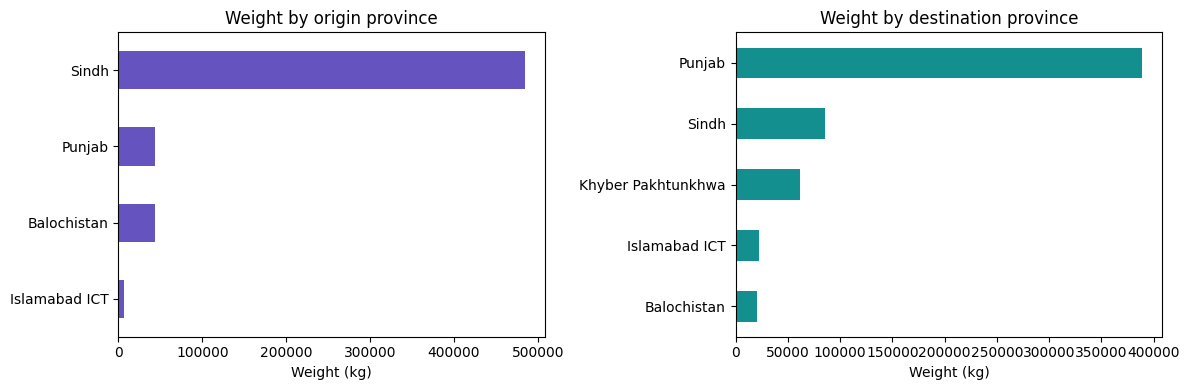

In [9]:
def report_data(mode=None, role='origin'):
    if role not in ['origin','destination']: raise ValueError('Choose origin or destination')
    d=fact.copy()
    if mode is not None:
        keys=tables['DimMode'].loc[tables['DimMode'].ModeName.str.lower().eq(mode.lower()),'ModeKey']
        if keys.empty: raise ValueError('Unknown mode')
        d=d[d.ModeKey.isin(keys)]
    fk='OriginCityKey' if role=='origin' else 'DestCityKey'
    d=d.merge(city[['CityKey','Province']],left_on=fk,right_on='CityKey',validate='many_to_one')
    d=d.merge(tables['DimDate'][['DateKey','MonthNumber','MonthName']],on='DateKey',validate='many_to_one')
    w=d.WeightKG.sum(); c=d.FreightCostPKR.sum()
    summary=pd.Series({'Total Weight':w,'Total Cost':c,'Shipment Count':d.ShipmentCount.sum(),
        'Cost per KG':c/w if w else float('nan'),'Distinct Cities (origin)':d.OriginCityKey.nunique()})
    matrix=d.pivot_table(index='Province',columns=['MonthNumber','MonthName'],values='WeightKG',aggfunc='sum',fill_value=0,margins=True,margins_name='Total')
    detail=d.groupby('ShipmentID').agg(Total_Weight=('WeightKG','sum'),Total_Cost=('FreightCostPKR','sum'))
    detail['Cost per KG']=detail.Total_Cost.div(detail.Total_Weight.replace(0,float('nan')))
    return summary,matrix,detail

def show_report(mode=None, role='origin'):
    s,m,d=report_data(mode,role)
    print('Mode:',mode or 'All','| Geography:',role)
    display(s.to_frame('Value'));display(m);display(d)
show_report()
summary,matrix,detail=report_data()
matrix.to_csv(OUT/'origin_province_month_matrix.csv');detail.to_csv(OUT/'shipment_detail.csv')
print('Correct ratio:',fact.FreightCostPKR.sum()/fact.WeightKG.sum())
print('Incorrect unweighted mean of row ratios:',(fact.FreightCostPKR/fact.WeightKG).mean())
# Independently validate each Mode selection and additive partition totals.
mode_results=[]
for mode in tables['DimMode'].query('ModeKey != -1').ModeName:
    s,m,d=report_data(mode)
    mode_results.append({'Mode':mode,**s.to_dict()})
mode_results=pd.DataFrame(mode_results)
assert mode_results['Total Weight'].sum()==fact.WeightKG.sum()
assert mode_results['Total Cost'].sum()==fact.FreightCostPKR.sum()
display(mode_results);mode_results.to_csv(OUT/'mode_summary.csv',index=False)
_,dest_matrix,_=report_data(role='destination');display(dest_matrix)
dest=fact.merge(city[['CityKey','Province']],left_on='DestCityKey',right_on='CityKey',validate='many_to_one')
assert dest.Province.nunique()==5
fig,axes=plt.subplots(1,2,figsize=(12,4))
origin.groupby('Province').WeightKG.sum().sort_values().plot.barh(ax=axes[0],color='#6554c0',title='Weight by origin province')
dest.groupby('Province').WeightKG.sum().sort_values().plot.barh(ax=axes[1],color='#138f90',title='Weight by destination province')
for ax in axes: ax.set_xlabel('Weight (kg)');ax.set_ylabel('')
fig.tight_layout();fig.savefig(OUT/'province_comparison.png',dpi=160,bbox_inches='tight');plt.show()


### Power BI implementation notes and measures
1. Import the original six star tables. Disable relationship autodetection and refresh-time relationship changes; remove unintended detected relationships.
2. Set all keys to Whole Number. Use the audited unique nonblank dimension keys.
3. Create exactly the six T4 relationships: one side on dimensions, Single flow toward FactShipment, only destination inactive.
4. Set FullDate to Date, mark DimDate as the date table, and sort MonthName by MonthNumber. This supplied date table covers February 2026 only; extend it for broader time-intelligence requirements.
5. Add the five measures below, plus the destination and diagnostic measures as needed. Ratio uses sums, not average of ratios.
6. Hide all `*Key` columns, including Route's origin/destination keys; keep ShipmentID visible.
7. Matrix: DimCity[Province] × DimDate[MonthName], [Total Weight]. Mode slicer: DimMode[ModeName]. Cards: Total Weight / Total Cost. Shipment detail: ShipmentID, Total Weight, Cost per KG. Use the destination measure for a destination matrix.
8. Test every Mode option and reset filters before T7. Independently verify actual Model view settings, save a `.pbix`, and submit it only if the instructor still requires the separate Power BI deliverable.

No Power BI screenshots or live model results are fabricated here.

```dax
Total Weight = SUM( FactShipment[WeightKG] )

Total Cost = SUM( FactShipment[FreightCostPKR] )

Shipment Count = SUM( FactShipment[ShipmentCount] )

Cost per KG = DIVIDE( [Total Cost], [Total Weight] )

Distinct Cities = DISTINCTCOUNT( FactShipment[OriginCityKey] )

Weight to Destination City =
CALCULATE( [Total Weight],
    USERELATIONSHIP( FactShipment[DestCityKey], DimCity[CityKey] )
)

Origin Province Count =
COUNTROWS(
    SUMMARIZE( FactShipment, DimCity[Province] )
)

Mode Has Shipments = IF( [Shipment Count] > 0, 1, 0 )
```

Create each definition as a separate measure. For the dependent Mode slicer in T5, apply `Mode Has Shipments = 1` as its visual-level filter. For RLS, validate the active-origin security semantics separately; USERELATIONSHIP is not a replacement for an appropriate security design.

## Conclusion
PakFreight should retain the flat City dimension and the six-relationship star with the destination role inactive. All 13 notebook checks pass, and the source reconciles to **578,650 kg** and **PKR 4,808,000**. The supplied snowflake's Region dependency is invalid, and the storage assumption discrepancy is disclosed. Notebook execution verifies Python calculations; native Power BI configuration remains a separate application step.